# Estimation

## Expected Value and Variance of the Maximum Likelihood Estimate

:::{.callout-important}
## Estimator

When we study the statistical properties of an estimator (a function of the observations) we must view it as a function (a random variable).
:::

[[1 1 1 ... 0 1 0]
 [1 0 0 ... 0 0 1]
 [1 0 0 ... 1 1 0]
 ...
 [0 0 0 ... 0 1 0]
 [0 1 0 ... 1 0 0]
 [0 1 1 ... 1 0 0]]
[0.306 0.307 0.278 0.303 0.293 0.289 0.285 0.291 0.291 0.337 0.298 0.311
 0.304 0.291 0.308 0.287 0.283 0.301 0.287 0.282 0.307 0.281 0.304 0.322
 0.318 0.322 0.304 0.333 0.316 0.273 0.319 0.288 0.3   0.295 0.322 0.312
 0.313 0.305 0.309 0.276 0.312 0.324 0.298 0.299 0.316 0.306 0.314 0.306
 0.272 0.326 0.3   0.283 0.308 0.306 0.292 0.327 0.289 0.328 0.31  0.276
 0.318 0.305 0.285 0.343 0.321 0.328 0.33  0.284 0.282 0.325 0.305 0.315
 0.314 0.315 0.314 0.312 0.315 0.307 0.319 0.303 0.305 0.311 0.318 0.308
 0.307 0.293 0.278 0.302 0.287 0.285 0.286 0.297 0.302 0.288 0.315 0.301
 0.314 0.325 0.287 0.292]
Mean of the ML estimates: 0.30384
Variance of the ML estimates: 0.00024111440000000023


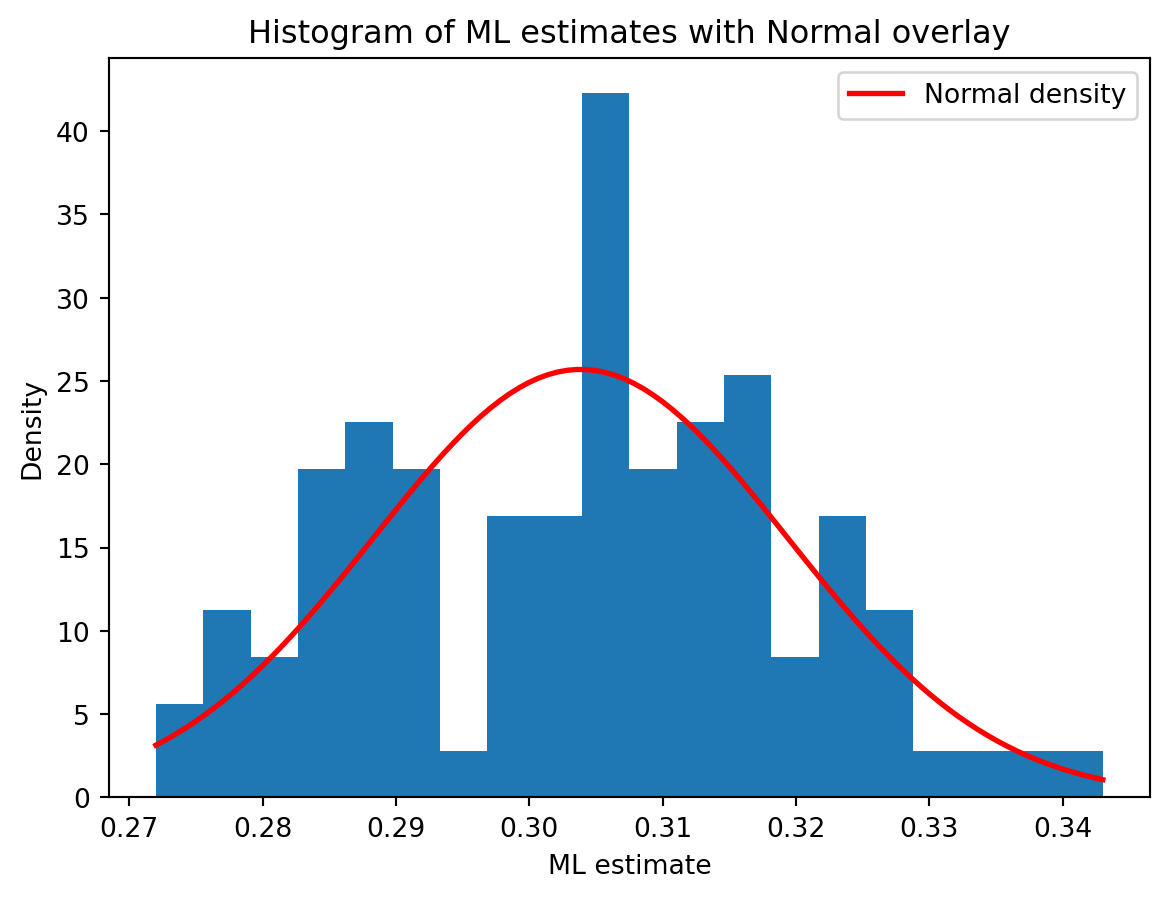

In [1]:
# Let's see how the ML estimate behaves in a simulation

import numpy as np
import matplotlib.pyplot as plt

# Number of samples
R = 100

# Sample size
n = 1000

# True parameter
p = 0.3

# Generate the samples

simulations = np.random.binomial(1, p, (R, n))

print(simulations)
# Compute the ML estimate for each sample (this is simply the sample mean)

p_ml = np.mean(simulations, axis=1)
print(p_ml)
# Plot the histogram of the ML estimates

# The mean of the ML estimates is equal to the true parameter (you need a lot of samples to see this)

print('Mean of the ML estimates:', np.mean(p_ml))

# The variance of the ML estimates is the true variance divided by the sample size

print('Variance of the ML estimates:', np.var(p_ml))


plt.hist(p_ml, bins=20, density=True)

# Overlay normal density
x = np.linspace(p_ml.min(), p_ml.max(), 100)
mean_ml = np.mean(p_ml)
var_ml = np.var(p_ml)
y_norm_dens = 1 / np.sqrt(2 * np.pi * var_ml) * np.exp(- (x - mean_ml)**2 / (2 * var_ml))


plt.plot(x, y_norm_dens, color='red', linewidth=2, label='Normal density')

plt.xlabel('ML estimate')
plt.ylabel('Density')
plt.title('Histogram of ML estimates with Normal overlay')
plt.legend()
plt.show()


## A Confidence Interval for p

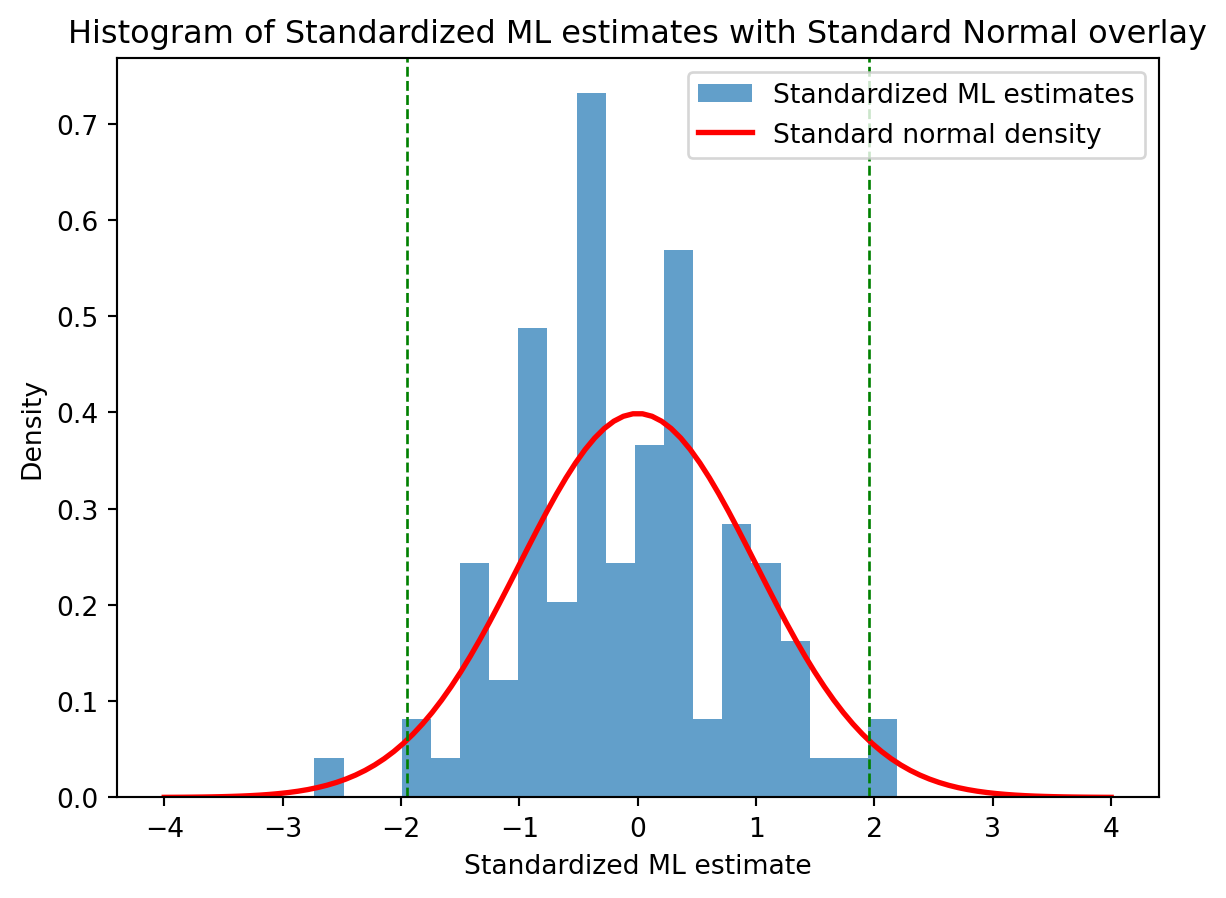

Number of standardized ML estimates within the 95% interval: 97 out of 100


In [2]:
# Number of samples
R = 100

# Sample size
n = 200

# True parameter
p = 0.3

# Generate the samples

simulations = np.random.binomial(1, p, (R, n))

# Compute the ML estimate for each sample (this is simply the sample mean)

p_ml = np.mean(simulations, axis=1)

# Compute the standardized version of the ML estimator
p_ml_std = (p_ml - p) / np.sqrt(p_ml * (1 - p_ml) / n)

# Plot histogram of the standardized ML estimator
plt.hist(p_ml_std, bins=20, density=True, alpha=0.7, label='Standardized ML estimates')

# Overlay standard normal density
z = np.linspace(-4, 4, 100)

plt.plot(z, 1/np.sqrt(2 * np.pi) * np.exp(-z**2 / 2), color='red', linewidth=2, label='Standard normal density')

plt.xlabel('Standardized ML estimate')

plt.axvline(-1.95, color='green', linestyle='dashed', linewidth=1)
plt.axvline(1.95, color='green', linestyle='dashed', linewidth=1)

plt.ylabel('Density')
plt.title('Histogram of Standardized ML estimates with Standard Normal overlay')
plt.legend()
plt.show()

# Print how many standardized estimates fall within the 95% interval

within_95 = np.sum((p_ml_std >= -1.95) & (p_ml_std <= 1.95))
print(f'Number of standardized ML estimates within the 95% interval: {within_95} out of {R}')

In [3]:
from scipy.stats import norm

# Compute the 97.5% quantile of the standard normal distribution (for a 95% confidence interval)

p  = 0.975

z_p = norm.ppf(p)
print(f"{100 * p}% quantile of the standard normal distribution: {z_p:.4f}")

# The cumulative distribution function (CDF) at z_p

print(f"norm.cdf(z_p) = {norm.cdf(z_p):.4f}")

97.5% quantile of the standard normal distribution: 1.9600
norm.cdf(z_p) = 0.9750


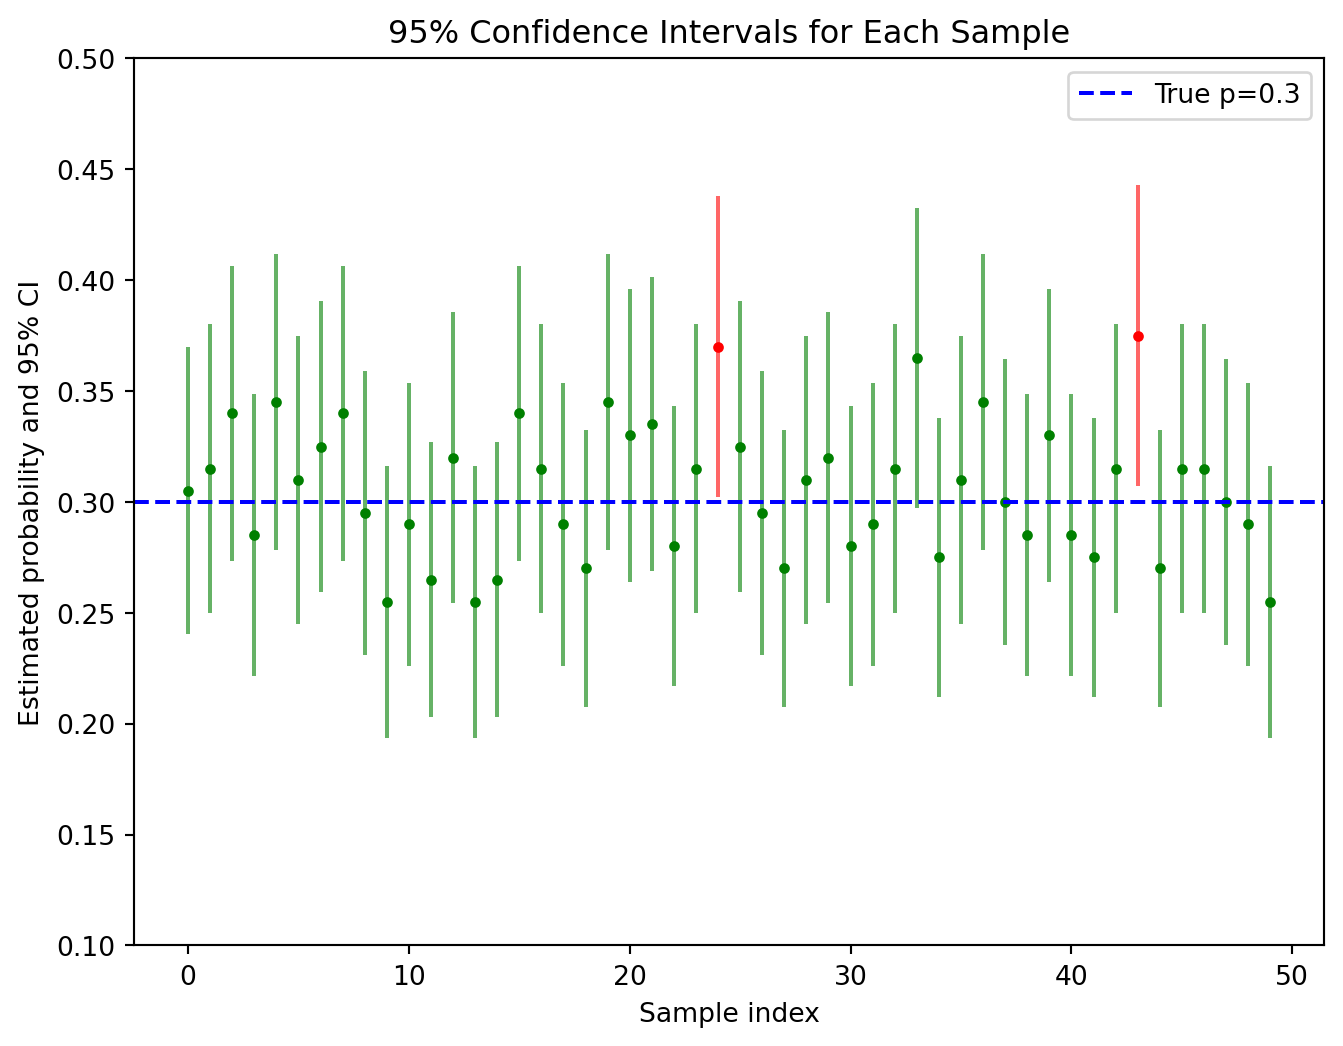

In [4]:
# Compute 95% confidence intervals for each sample's ML estimate
alpha = 0.05
z_critical = norm.ppf(1 - alpha/2)  # ≈ 1.96

# Use only the first 50 samples for plotting
p_ml_plot = p_ml[:50]

# For each selected sample, calculate the standard error and CI
se = np.sqrt(p_ml_plot * (1 - p_ml_plot) / n)
ci_lower = p_ml_plot - z_critical * se
ci_upper = p_ml_plot + z_critical * se

# Determine if the true value 0.3 is within each CI
contains_true = (ci_lower <= 0.3) & (ci_upper >= 0.3)

# Plot the confidence intervals
plt.figure(figsize=(8, 6))
for i in range(len(p_ml_plot)):
    color = 'green' if contains_true[i] else 'red'
    plt.plot([i, i], [ci_lower[i], ci_upper[i]], color=color, alpha=0.6)
    plt.plot(i, p_ml_plot[i], 'o', color=color, markersize=3)

plt.axhline(0.3, color='blue', linestyle='--', label='True p=0.3')
plt.ylim(0.1, 0.5)
plt.xlabel('Sample index')
plt.ylabel('Estimated probability and 95% CI')
plt.title('95% Confidence Intervals for Each Sample')
plt.legend()
plt.show()

## Estimation of a Normal Distribution Mean

## Estimation of a Normal Distribution Variance

In [5]:
# Sample from a normal distribution with mean 0 and variance 1

R = 10000
n = 10

normal_samples = np.random.normal(0, 1, (R, n))

# Compute the ML estimate for mu for each sample (this is simply the sample mean)

p_ml = np.mean(normal_samples, axis=1)

# Print the average of the ML estimates

print('Mean of the ML estimates:', np.mean(p_ml))

Mean of the ML estimates: 0.005817322543320051


In [6]:
# Calculate the ML estimate for the variance

ml_estimate_variance = np.var(normal_samples, axis=1, ddof=0)

# Print the average of the ML estimates for the variance

print('Mean of the ML estimates for the variance:', np.mean(ml_estimate_variance))

Mean of the ML estimates for the variance: 0.9019585052690975


In [7]:
# Calculate the corrected ML estimate for the variance

ml_estimate_variance_corrected = np.var(normal_samples, axis=1, ddof=1)

# Print the average of the corrected ML estimates for the variance

print('Mean of the corrected ML estimates for the variance:', np.mean(ml_estimate_variance_corrected))

Mean of the corrected ML estimates for the variance: 1.0021761169656638


:::{#ex-estimation-1}

## Probability Estimation Exercise

You take random sample of 1000 persons and ask them about their political preferences. 231 of them state they would support party A in the next elections. Estimate the share of supporters of party A in the population and construct a 95% confidence interval for this share.  Can you confidently claim that party A has the support of more than 35% of the population?

:::